In [1]:
import mplhep as hep
from scipy import interpolate
import matplotlib.pyplot as plt
import numpy as np

In [2]:
## Value from YR4
x_values = {
    7: np.array([125.0, 125.09, 125.1, 125.2, 125.3, 125.4, 125.5, 125.6, 125.7, 125.8, 125.9, 126.0, 126.5, 127.0]),
    8: np.array([125.0, 125.09, 125.1, 125.2, 125.3, 125.4, 125.5, 125.6, 125.7, 125.8, 125.9, 126.0, 126.5, 127.0]),
    13: np.array([125.0, 125.09, 125.1, 125.2, 125.3, 125.4, 125.5, 125.6, 125.7, 125.8, 125.9, 126.0, 126.5, 127.0]),
    14: np.array([125.0, 125.09, 125.1, 125.2, 125.3, 125.4, 125.5, 125.6, 125.7, 125.8, 125.9, 126.0, 126.5, 127.0])
}

y_values_ggH = {
    7: np.array([16.85, 16.82, 16.82, 16.79, 16.77, 16.74, 16.71, 16.68, 16.66, 16.63, 16.60, 16.58, 16.44, 16.31]),
    8: np.array([21.42, 21.39, 21.39, 21.36, 21.32, 21.29, 21.26, 21.22, 21.19, 21.16, 21.12, 21.09, 20.92, 20.76]),
    13: np.array([48.58, 48.52, 48.51, 48.44, 48.37, 48.30, 48.23, 48.16, 48.10, 48.03, 47.96, 47.89, 47.56, 47.23]),
    14: np.array([54.67, 54.61, 54.60, 54.52, 54.45, 54.37, 54.29, 54.22, 54.14, 54.07, 53.99, 53.92, 53.55, 53.18])
}

y_values_VBF = {
    7: np.array([1.241, 1.24, 1.24, 1.239, 1.238, 1.237, 1.236, 1.235, 1.233, 1.232, 1.231, 1.23, 1.224, 1.218]),
    8: np.array([1.601, 1.600, 1.600, 1.598, 1.597, 1.596, 1.594, 1.593, 1.591, 1.590, 1.588, 1.587, 1.580, 1.573]),
    13: np.array([3.782, 3.779, 3.779, 3.776, 3.773, 3.770, 3.767, 3.764, 3.761, 3.758, 3.755, 3.752, 3.738, 3.723]),
    14: np.array([4.278, 4.275, 4.275, 4.272, 4.268, 4.265, 4.262, 4.258, 4.255, 4.252, 4.249, 4.245, 4.229, 4.213])
}

y_values_WH = {
    7: np.array([0.5771, 0.5756, 0.5756, 0.5740, 0.5725, 0.5708, 0.5694, 0.5679, 0.5665, 0.5650, 0.5633, 0.5618, 0.5542, 0.5469]),
    8: np.array([0.7026, 0.7009, 0.7009, 0.6989, 0.6969, 0.6950, 0.6930, 0.6912, 0.6895, 0.6875, 0.6859, 0.6840, 0.6749, 0.6660]),
    13: np.array([1.373, 1.369, 1.369, 1.365, 1.362, 1.358, 1.355, 1.351, 1.347, 1.344, 1.341, 1.337, 1.320, 1.304]),
    14: np.array([1.513, 1.510, 1.510, 1.506, 1.502, 1.498, 1.494, 1.490, 1.487, 1.483, 1.479, 1.476, 1.456, 1.437])
}

y_values_ZH = {
    7: np.array([0.3392, 0.3384, 0.3383, 0.3375, 0.3366, 0.3357, 0.3348, 0.3339, 0.3333, 0.3325, 0.3315, 0.3307, 0.3265, 0.3225]),
    8: np.array([0.4208, 0.4199, 0.4199, 0.4187, 0.4176, 0.4166, 0.4157, 0.4148, 0.4136, 0.4128, 0.4119, 0.4107, 0.4056, 0.4008]),
    13: np.array([0.8839, 0.8824, 0.8819, 0.8800, 0.8783, 0.8767, 0.8744, 0.8728, 0.8703, 0.8690, 0.8668, 0.8649, 0.8549, 0.8446]),
    14: np.array([0.9861, 0.9836, 0.9835, 0.9815, 0.9794, 0.977, 0.9745, 0.9727, 0.9701, 0.9676, 0.9656, 0.9626, 0.9526, 0.9422])
}

y_values_ttH = {
    7: np.array([0.08878, 0.08864, 0.08873, 0.08841, 0.08825, 0.08794, 0.08783, 0.08761, 0.08742, 0.08714, 0.08703, 0.08674, 0.08571, 0.08477]),
    8: np.array([0.1330, 0.1326, 0.1327, 0.1324, 0.1321, 0.1316, 0.1314, 0.1310, 0.1306, 0.1305, 0.1302, 0.1299, 0.1282, 0.1266]),
    13: np.array([0.5071, 0.5065, 0.5060, 0.5052, 0.5043, 0.5033, 0.5023, 0.5007, 0.4993, 0.4982, 0.4971, 0.4964, 0.4909, 0.4851]),
    14: np.array([0.6137, 0.6128, 0.6127, 0.6121, 0.6100, 0.6089, 0.6075, 0.6056, 0.6044, 0.6035, 0.6022, 0.6009, 0.5938, 0.5874])
}

en 7
18.976015727526814


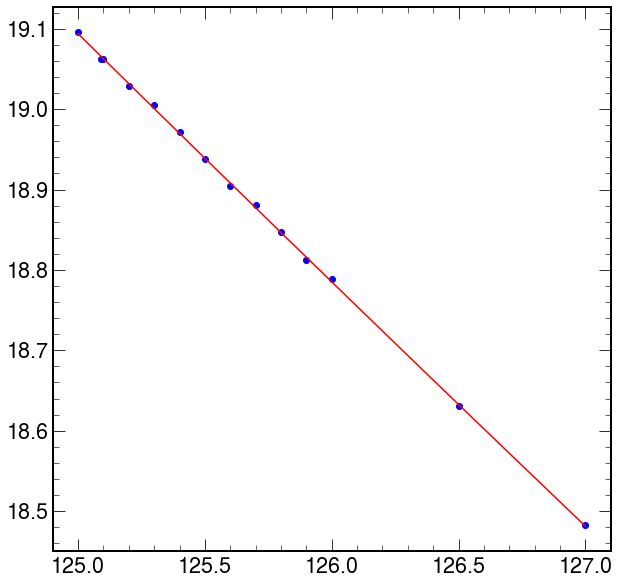

en 8
24.13578739760311


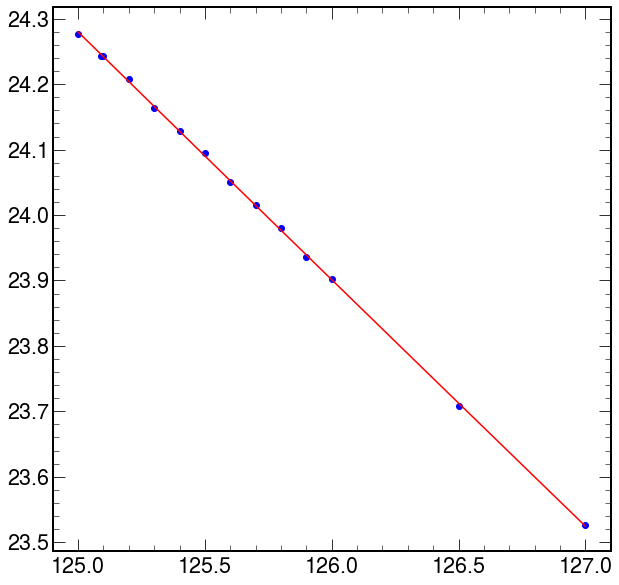

en 13
54.82476174103192


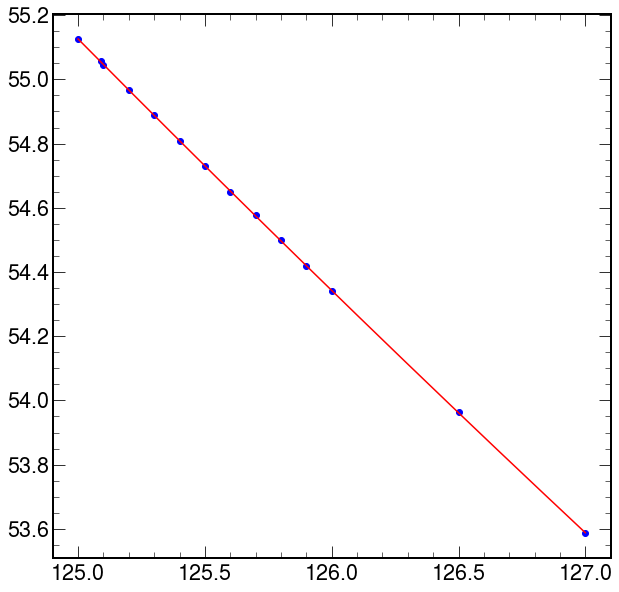

en 14
61.7358007864521


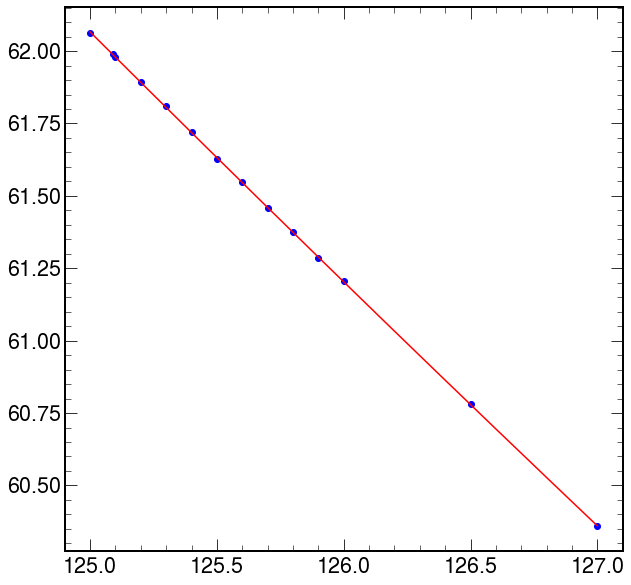

In [14]:
## Extrapolation at 125.38 for theoretical XS
for en in [7, 8,13,14]:
    print('en', en)
    y_values = y_values_ggH[en] + y_values_VBF[en] + y_values_WH[en] + y_values_ZH[en] + y_values_ttH[en]
    plt.scatter(x_values[en], y_values, color='blue', label='Data points')
    coefficients = np.polyfit(x_values[en], y_values, 2)
    polynomial = np.poly1d(coefficients)
    x_fit = np.linspace(min(x_values[en]), max(x_values[en]), 500)
    y_fit = polynomial(x_fit)
    plt.plot(x_fit, y_fit, color='red', label='Fitted polynomial')
    print(np.polyval(coefficients, 125.38))
    plt.show()

# Plotter

In [4]:
## Without 7 TeV Hgg

# x_value_plot_125_38 = np.array([8, 13, 14])
# y_values_plot_125_38 = np.array([24.14, 54.82, 61.74])

# x_value_plot_125 = np.array([8, 13, 14])
# y_values_plot_125 = np.array([24.28, 55.13, 62.06])

# y_unc_up = np.array([1.22, 3.08, 3.14])
# y_unc_dn = np.array([1.68, 3.92, 4.32])

# x_meas = np.array([8, 13, 13.6])
# y_meas = np.array([24.28, 53.32, 67.84])
# y_err_up = np.array([7.89, 4.43, 11.31])
# y_err_dn = np.array([7.89, 4.29, 10.44])


## With 7 TeV Hgg
x_value_plot_125_38 = np.array([7, 8, 13, 14])
y_values_plot_125_38 = np.array([18.98, 24.14, 54.82, 61.74])

x_value_plot_125 = np.array([7, 8, 13, 14])
y_values_plot_125 = np.array([19.10, 24.28, 55.13, 62.06])

y_unc_up = np.array([0.971, 1.22, 3.08, 3.14])
y_unc_dn = np.array([1.347, 1.68, 3.92, 4.32])

x_meas = np.array([7, 8, 13, 13.6])
y_meas = np.array([42.402, 24.28, 53.32, 64.36])
y_err_up = np.array([10.887, 7.89, 4.43, 10.43])
y_err_dn = np.array([9.359, 7.89, 4.29, 10.44])

x_meas_HZZ = np.array([7, 8, 13, 13.6])
y_meas_HZZ = np.array([11.50, 23.44, 52.28, 56.11])
y_err_up_HZZ = np.array([14.38, 9.08, 4.98, 11.45])
y_err_dn_HZZ = np.array([9.04, 7.60, 4.98, 10.31])

In [5]:
plt.style.use(hep.style.CMS)

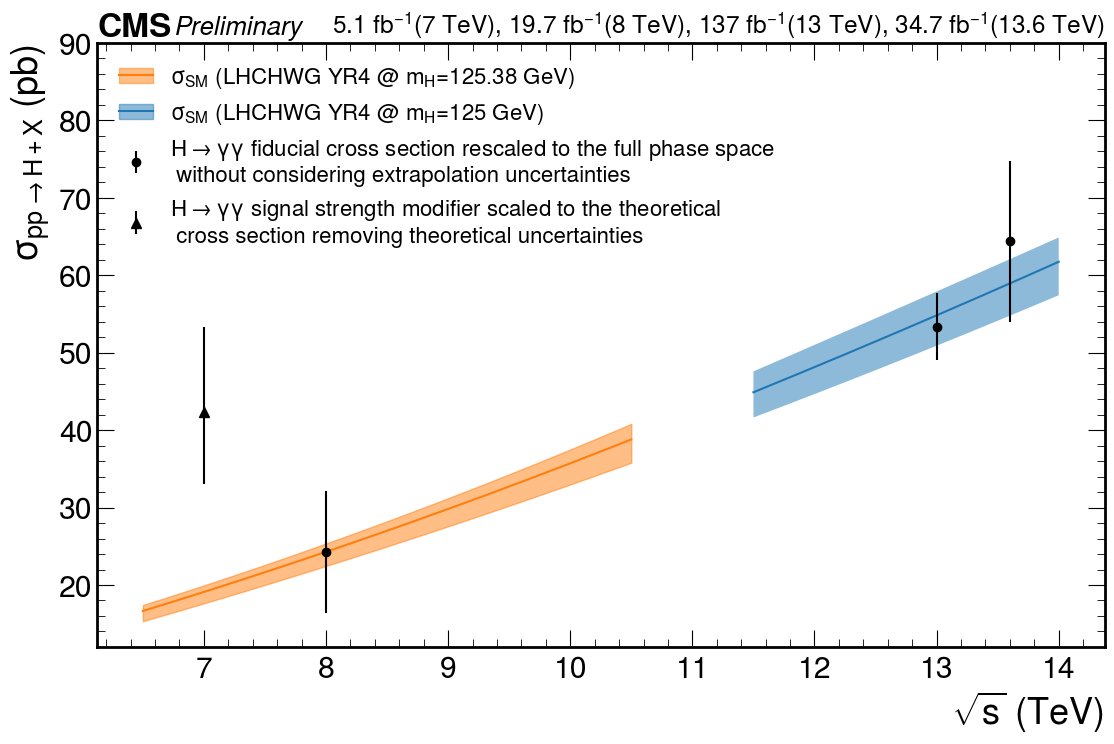

In [8]:
plt.figure(figsize=(13,8), dpi=100)
hep.cms.label(llabel= 'Preliminary', rlabel=r'5.1 fb$^{-1}$(7 TeV), 19.7 fb$^{-1}$(8 TeV), 137 fb$^{-1}$(13 TeV), 34.7 fb$^{-1}$(13.6 TeV)', fontsize=18.5)

#125.38
spline = interpolate.splrep(x_value_plot_125_38, y_values_plot_125_38, k=2)
x = np.linspace(11.5, 14, 200)
y = interpolate.splev(x, spline)
p12538 = plt.plot(x,y, label=r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125.38 GeV)', color='tab:blue')

#125
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125, k=2)
x = np.linspace(6.5, 10.5, 200)
y = interpolate.splev(x, spline)
p125 = plt.plot(x,y, label=r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125 GeV)', color='tab:orange')

#Errors_125_38
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 + y_unc_up , k=2)
x = np.linspace(11.5, 14, 200)
y_up = interpolate.splev(x, spline)
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 - y_unc_dn, k=2)
y_dn = interpolate.splev(x, spline)
plt.fill_between(x, y_up, y_dn, alpha=0.5)

#Errors_125
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 + y_unc_up , k=2)
x = np.linspace(6.5, 10.5, 200)
y_up = interpolate.splev(x, spline)
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 - y_unc_dn, k=2)
y_dn = interpolate.splev(x, spline)
plt.fill_between(x, y_up, y_dn, alpha=0.5, color='tab:orange')

data_7 = plt.errorbar(x_meas[1:], y_meas[1:], yerr = [y_err_dn[1:], y_err_up[1:]], c='black', fmt= 'o', label=r'$H\rightarrow\gamma\gamma$' ' fiducial cross section rescaled to the full phase space \n without considering extrapolation uncertainties')
data = plt.errorbar(x_meas[0], y_meas[0], yerr = [[y_err_dn[0]], [y_err_up[0]]], c='black', fmt= '^', markersize=7, label=r'$H\rightarrow\gamma\gamma$' ' signal strength modifier scaled to the theoretical \n cross section removing theoretical uncertainties')

f12538 = plt.fill(np.NaN, np.NaN, alpha=0.5, color='tab:blue')
f125 = plt.fill(np.NaN, np.NaN, alpha=0.5, color='tab:orange')
plt.ylim([12,90])
plt.xlabel(r'$\sqrt{s}$ (TeV)')
plt.ylabel(r'$\sigma_{pp\rightarrow H+X}$ (pb)')
# plt.legend(loc='upper left', fontsize=16)
plt.legend([(p125[0], f125[0]), (p12538[0], f12538[0]), data_7, data], [r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125.38 GeV)', 
                                                                         r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125 GeV)',
                                                                         r'$H\rightarrow\gamma\gamma$' ' fiducial cross section rescaled to the full phase space \n without considering extrapolation uncertainties',
                                                                         r'$H\rightarrow\gamma\gamma$' ' signal strength modifier scaled to the theoretical \n cross section removing theoretical uncertainties'
                                                                        ], loc='upper left', fontsize=16)
# plt.text(6.4, 58, 'Fiducial cross sections are rescaled to the full phase \n space without considering extrapolation uncertainties', fontsize=15, fontfamily='sans-serif')
plt.savefig('XSvsSqrts.pdf', dpi=100, bbox_inches='tight')
plt.show()

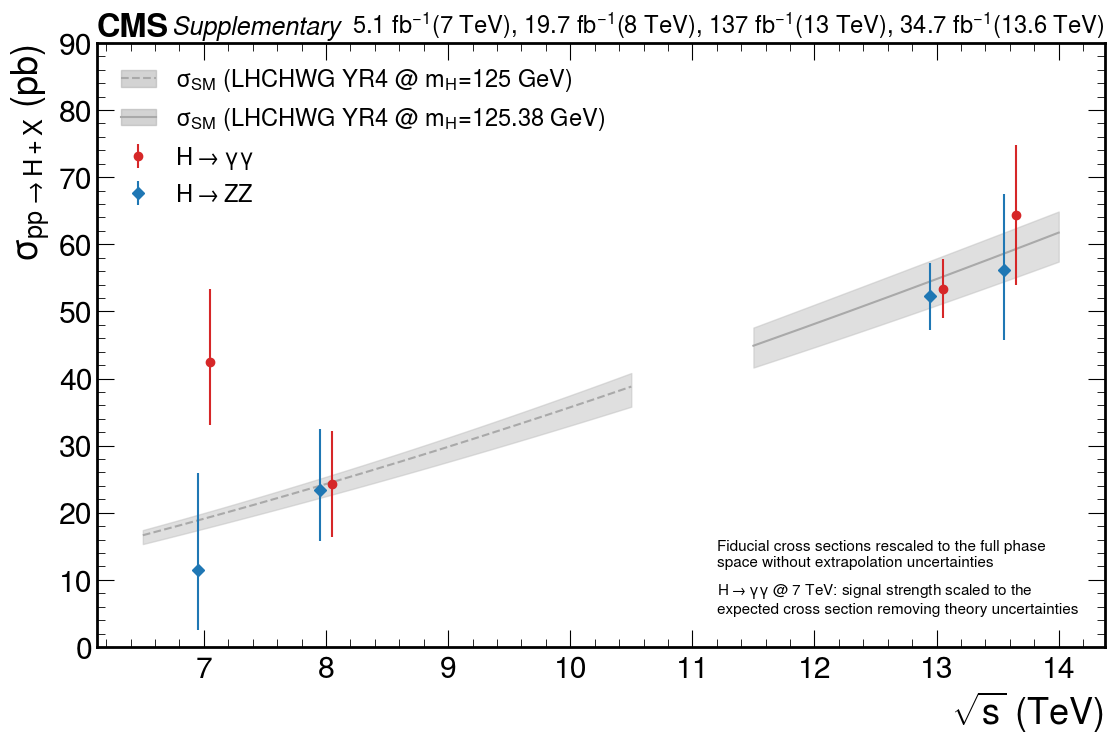

In [8]:
plt.figure(figsize=(13,8), dpi=100)
hep.cms.label(llabel= 'Supplementary', rlabel=r'5.1 fb$^{-1}$(7 TeV), 19.7 fb$^{-1}$(8 TeV), 137 fb$^{-1}$(13 TeV), 34.7 fb$^{-1}$(13.6 TeV)', fontsize=18)

#125.38
spline = interpolate.splrep(x_value_plot_125_38, y_values_plot_125_38, k=2)
x = np.linspace(11.5, 14, 200)
y = interpolate.splev(x, spline)
p12538 = plt.plot(x,y, label=r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125.38 GeV)', color='darkgrey')

#125
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125, k=2)
x = np.linspace(6.5, 10.5, 200)
y = interpolate.splev(x, spline)
p125 = plt.plot(x,y, label=r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125 GeV)', color='darkgrey', ls='--')

#Errors_125_38
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 + y_unc_up , k=2)
x = np.linspace(11.5, 14, 200)
y_up = interpolate.splev(x, spline)
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 - y_unc_dn, k=2)
y_dn = interpolate.splev(x, spline)
plt.fill_between(x, y_up, y_dn, alpha=0.5, color='silver')

#Errors_125
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 + y_unc_up , k=2)
x = np.linspace(6.5, 10.5, 200)
y_up = interpolate.splev(x, spline)
spline = interpolate.splrep(x_value_plot_125, y_values_plot_125_38 - y_unc_dn, k=2)
y_dn = interpolate.splev(x, spline)
plt.fill_between(x, y_up, y_dn, alpha=0.5, color='silver')

data_Hgg = plt.errorbar(x_meas+0.05, y_meas, yerr = [y_err_dn, y_err_up], c='tab:red', fmt= 'o', label=r'$H\rightarrow\gamma\gamma$')
# data = plt.errorbar(x_meas[0]+0.05, y_meas[0], yerr = [[y_err_dn[0]], [y_err_up[0]]], c='black', fmt= 'o', markersize=7, label=r'$H\rightarrow\gamma\gamma$' ' signal strength modifier scaled to the theoretical \n cross section removing theoretical uncertainties')

data_HZZ = plt.errorbar(x_meas_HZZ-0.05, y_meas_HZZ, yerr = [y_err_dn_HZZ, y_err_up_HZZ], c='tab:blue', fmt= 'D', label=r'$H\rightarrow ZZ$')


f12538 = plt.fill(np.NaN, np.NaN, alpha=0.5, color='darkgrey')
f125 = plt.fill(np.NaN, np.NaN, alpha=0.5, color='darkgrey')
plt.ylim([0,90])
plt.xlabel(r'$\sqrt{s}$ (TeV)')
plt.ylabel(r'$\sigma_{pp\rightarrow H+X}$ (pb)')
# plt.legend(loc='upper left', fontsize=18)
plt.legend([(p125[0], f125[0]), (p12538[0], f12538[0]), data_Hgg, data_HZZ], [r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125 GeV)', 
                                                                              r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125.38 GeV)',
                                                                              r'$H\rightarrow\gamma\gamma$',
                                                                              r'$H\rightarrow ZZ$'
                                                                              ], loc='upper left', fontsize=17)
plt.text(11.2, 12, 'Fiducial cross sections rescaled to the full phase \nspace without extrapolation uncertainties', fontsize=11, fontfamily='sans-serif')
plt.text(11.2, 5, r'$H\rightarrow\gamma\gamma$ @ 7 TeV:' ' signal strength scaled to the \nexpected cross section removing theory uncertainties', fontsize=11, fontfamily='sans-serif')
plt.savefig('XSvsSqrts_withHZZ.pdf', dpi=100, bbox_inches='tight')
plt.show()

# 2022-2024: 13.6 TeV results (with and without the expected combination)

In [ ]:
## 13 TeV, Run 2 (138 fb-1): total cross sections extrapolated to the full phase space (acceptance uncertainties in
## the fit) of CMS-HIG-23-013, JHEP 04 (2026) 093, Section 6 (value, up, down) in pb
run2_13 = {
    'Hgg': (54.2, 4.5, 4.3),
    'HZZ': (53.3, 5.2, 5.0),
    'comb': (53.4, 3.5, 3.4),
}

## 13.6 TeV, 2022-2024 (172 fb-1): total cross sections r * sigma_SM with the -2 Delta lnL = 1 intervals of the
## inclusive scans (models of AN-26-236, spline crossings as in Plots/plotInclusiveCombination.py)
sigma_sm_136 = 59.21
## observed, single channels (value, up, down) in pb:
##   Hgg: output_combination_accbin_inclusive/hgg/Combine/runFits_mu_fiducial/dataFit
##   HZZ: output_asimov_inclusive_HggH4l/h4l/Combine/runFits_mu_fiducial/dataFit
obs_136 = {
    'Hgg': (63.33, 5.67, 5.09),
    'HZZ': (61.12, 5.19, 4.93),
}
## expected (Asimov) combination, drawn at the SM value: (up, down) in pb
exp_comb_136 = (3.62, 3.51)

In [ ]:
## 7 and 8 TeV: the published per-channel results as ratios to their SM predictions, r = sigma_meas / sigma_pred,
## shown as sigma_tot = r * sigma_SM (YR4 at mH = 125 GeV, as the curve), without extrapolation uncertainties
##   Hgg 8 TeV: CMS-HIG-14-016 (EPJC 76 (2016) 13), Sec. 7.2: sigma_fid = 32 +-10 (stat) +-3 (syst) fb; HRES+XH 31 fb
##   HZZ 8 TeV: CMS-HIG-14-028 (JHEP 04 (2016) 005), Table 5: 1.11 +0.41-0.35 (stat) +0.14-0.10 (syst) +0.08-0.02 (model) fb;
##              HRES+XH 1.15 fb
##   HZZ 7 TeV: same Table 5: 0.56 +0.67-0.44 (stat) +0.21-0.06 (syst) +-0.02 (model) fb; HRES+XH 0.93 fb
##   Hgg 7 TeV: CMS-HIG-13-001 (EPJC 74 (2014) 3076), Table 5: mu = 2.22 +0.62-0.55 (mH profiled, best fit 124.2 GeV);
##              theory uncertainties removed as in the cells above: +0.570 -0.490
sigma_sm_run1 = {7: y_values_plot_125[0], 8: y_values_plot_125[1]}
run1_inputs = {  # (measured, [(up, down) of the uncertainty components], prediction)
    (8, 'Hgg'): (32, [(10, 10), (3, 3)], 31),
    (8, 'HZZ'): (1.11, [(0.41, 0.35), (0.14, 0.10), (0.08, 0.02)], 1.15),
    (7, 'HZZ'): (0.56, [(0.67, 0.44), (0.21, 0.06), (0.02, 0.02)], 0.93),
    (7, 'Hgg'): (2.22, [(0.570, 0.490)], 1.0),
}


def run1_ratio(E, ch):
    """(r, up, down), components added in quadrature"""
    meas, comps, pred = run1_inputs[(E, ch)]
    up, dn = (np.sqrt(sum(c[i]**2 for c in comps)) / pred for i in (0, 1))
    return meas / pred, up, dn


run1_points = {key: tuple(v * sigma_sm_run1[key[0]] for v in run1_ratio(*key)) for key in run1_inputs}  # pb
for (E, ch), (v, up, dn) in sorted(run1_points.items()):
    print(f"{E} TeV {ch}: {v:.2f} +{up:.2f} -{dn:.2f} pb")

In [ ]:
def sm_curve(x_points, y_points, xmin, xmax, ls):
    """SM prediction and its uncertainty band, both around the central values of the same mass"""
    x = np.linspace(xmin, xmax, 200)
    central = interpolate.splev(x, interpolate.splrep(x_points, y_points, k=2))
    up = interpolate.splev(x, interpolate.splrep(x_points, y_points + y_unc_up, k=2))
    dn = interpolate.splev(x, interpolate.splrep(x_points, y_points - y_unc_dn, k=2))
    line, = plt.plot(x, central, color='darkgrey', ls=ls)
    band = plt.fill_between(x, up, dn, alpha=0.5, color='silver')
    return (line, band)


def channel_points(key, x_7_8, x_13):
    """7 and 8 TeV of HIG-13-001 / HIG-14-016 / HIG-14-028, 13 TeV of HIG-23-013, 13.6 TeV of 2022-2024: (x, y, down, up)"""
    pts = [run1_points[(7, key)], run1_points[(8, key)], run2_13[key], obs_136[key]]
    return np.append(x_7_8, x_13), *(np.array([p[i] for p in pts]) for i in (0, 2, 1))


def plot_sqrts(with_comb, fname):
    plt.figure(figsize=(13, 8), dpi=100)
    hep.cms.label(llabel='Internal', rlabel=r'5.1 fb$^{-1}$ (7 TeV), 19.7 fb$^{-1}$ (8 TeV), 138 fb$^{-1}$ (13 TeV), 172 fb$^{-1}$ (13.6 TeV)', fontsize=18)

    sm125 = sm_curve(x_value_plot_125, y_values_plot_125, 6.5, 10.5, '--')
    sm12538 = sm_curve(x_value_plot_125_38, y_values_plot_125_38, 11.5, 14, '-')

    # single channels: 7 and 8 TeV (HIG-13-001, HIG-14-016, HIG-14-028), 13 TeV (HIG-23-013) and 13.6 TeV (2022-2024)
    dx = 0.1 if with_comb else 0.05
    x, y, dn, up = channel_points('Hgg', [7.05, 8.05], [13 + dx, 13.6 + dx])
    hgg = plt.errorbar(x, y, yerr=[dn, up], c='tab:red', fmt='o')
    x, y, dn, up = channel_points('HZZ', [6.95, 7.95], [13 - dx, 13.6 - dx])
    hzz = plt.errorbar(x, y, yerr=[dn, up], c='tab:blue', fmt='D')
    handles = [sm125, sm12538, hgg, hzz]
    labels = [r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125 GeV)',
              r'$\sigma_{SM}$ (LHCHWG YR4 @ $m_{\rm H}$=125.38 GeV)',
              r'$H\rightarrow\gamma\gamma$',
              r'$H\rightarrow ZZ$']

    # combinations: 13 TeV (HIG-23-013), and 13.6 TeV expected, open marker at the SM value
    if with_comb:
        val, cu, cd = run2_13['comb']
        handles.append(plt.errorbar([13], [val], yerr=[[cd], [cu]], c='black', fmt='s', markersize=8))
        labels.append(r'$H\rightarrow\gamma\gamma$ + $H\rightarrow ZZ$')
        handles.append(plt.errorbar([13.6], [sigma_sm_136], yerr=[[exp_comb_136[1]], [exp_comb_136[0]]], c='black', fmt='s', mfc='white', mew=2, markersize=8))
        labels.append(r'$H\rightarrow\gamma\gamma$ + $H\rightarrow ZZ$, expected')

    plt.ylim([0, 90])
    plt.xlabel(r'$\sqrt{s}$ (TeV)')
    plt.ylabel(r'$\sigma_{pp\rightarrow H+X}$ (pb)')
    leg = plt.legend(handles[:4], labels[:4], loc='upper left', fontsize=16)
    if with_comb:
        plt.gca().add_artist(leg)
        plt.legend(handles[4:], labels[4:], loc='upper right', fontsize=16)
    plt.text(10.6, 19.5 if with_comb else 18, '7 and 8 TeV: fiducial cross sections rescaled to the full phase\nspace without extrapolation uncertainties', fontsize=11, fontfamily='sans-serif')
    plt.text(10.6, 13 if with_comb else 11.5, r'$H\rightarrow\gamma\gamma$ @ 7 TeV:' ' signal strength scaled to the expected cross\nsection removing theory uncertainties', fontsize=11, fontfamily='sans-serif')
    plt.text(10.6, 3 if with_comb else 5, '13 and 13.6 TeV: total cross sections, including the uncertainties\nin the acceptance' + ('\n13.6 TeV combination: expected, at the SM value' if with_comb else ''), fontsize=11, fontfamily='sans-serif')
    plt.savefig(fname, dpi=100, bbox_inches='tight')
    plt.show()

In [ ]:
plot_sqrts(False, 'XSvsSqrts_withHZZ_2022_2024.pdf')

In [ ]:
plot_sqrts(True, 'XSvsSqrts_withHZZ_combination_2022_2024.pdf')